# Algorithme des k-moyennes

Soit un ensemble de données d’apprentissage non labellisées en dimension 2 contenues dans le fichier
Data1.txt On dispose pour un ensemble d’exemples à classer de deux caractéristiques. Cet ensemble
d'apprentissage comprend 132 exemples qui ont été simulées selon 3 gaussiennes.

* Expliquer le principe de fonctionnement, la nature et les différentes étapes d’un algorithme de kmoyennes.


* Exécuter le programme Kmeans pour effectuer une classification non supervisée des données par un algorithme des k-moyennes.  En faisant varier le nombre de groupements réalisés par l’algorithme (k=2, 3, 5, 10, 15, 20), étudier les
variations de « l’inertie intra ». Que remarquez-vous ? Qu’en pensez-vous ? On fera une figure pour chaque cas et un tableau pour justifier les résultats, on indiquera la cardinalité de chaque groupe et la table de confusion.


* Frontière de décision :
On vous demande de représenter les frontières de décision dans le cas qui présente le moins de formes fortes de la question 3° précédente. Pour cela, vous aurez besoin de définir un ensemble constitué des points d’un maillage 2D; on vous propose les points de -1.8 à 1.8 par pas de 0.05 par exemple. 


* On appelle forme forte les éléments de l’ensemble d’apprentissage qui ont toujours été classés ensemble au cours de plusieurs classifications (initialisations différentes). Ecrire un script qui permet de trouver le nombre de formes fortes et la cardinalité de ces formes. Déterminer les formes fortes pour quelques valeurs de k (k=2, 3, 4, 5 par exemple), et faire 25 essais à chaque fois.



In [3]:
import sys
print(sys.executable)

c:\Users\Anis\AppData\Local\Python\pythoncore-3.13-64\python.exe


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

print("KMeans fonctionne !")

ImportError: DLL load failed while importing _kd_tree: Une stratégie de contrôle d’application a bloqué ce fichier.

In [4]:
import sys
!{sys.executable} -m pip install scikit-learn

  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------- ----------------------- 3.4/8.2 MB 22.9 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 24.0 MB/s  0:00:00
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.26.0-py3-none-any.whl (474 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 

In [7]:
import sys
print(sys.executable)

c:\Users\Anis\AppData\Local\Python\pythoncore-3.13-64\python.exe


In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
data = np.loadtxt("Data1.txt")

print("Dimensions :", data.shape)
print(data[:5])

Dimensions : (132, 2)
[[ 0.5541  0.2389]
 [-0.4038  0.1031]
 [ 0.664  -0.4733]
 [-0.178   0.578 ]
 [-1.1749  0.1001]]


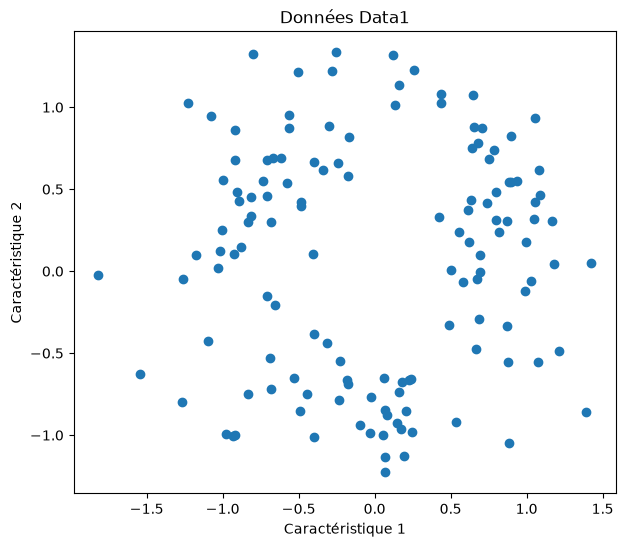

In [12]:
plt.figure(figsize=(7, 6))

plt.scatter(data[:, 0], data[:, 1])

plt.xlabel("Caractéristique 1")
plt.ylabel("Caractéristique 2")
plt.title("Données Data1")

plt.show()

In [13]:
def kmeans(X, k, max_iter=100):
    
    # 1. Choisir k points au hasard comme centroïdes initiaux
    indices = np.random.choice(len(X), k, replace=False)
    centres = X[indices].copy()

    for _ in range(max_iter):

        # 2. Calculer la distance de chaque point aux centroïdes
        distances = np.linalg.norm(
            X[:, np.newaxis] - centres,
            axis=2
        )

        # 3. Affecter chaque point au centroïde le plus proche
        labels = np.argmin(distances, axis=1)

        # 4. Recalculer les centroïdes
        nouveaux_centres = np.array([
            X[labels == i].mean(axis=0)
            for i in range(k)
        ])

        # 5. Vérifier si les centroïdes ne bougent plus
        if np.allclose(centres, nouveaux_centres):
            centres = nouveaux_centres
            break

        centres = nouveaux_centres

    # 6. Calcul de l'inertie intra
    inertie = np.sum((X - centres[labels]) ** 2)

    return labels, centres, inertie

In [14]:
np.random.seed(0)

labels, centres, inertie = kmeans(data, 2)

print("Centroïdes :")
print(centres)

print("\nInertie intra :", inertie)

Centroïdes :
[[ 0.56902639 -0.12149028]
 [-0.68283333  0.28511833]]

Inertie intra : 81.61542362622222


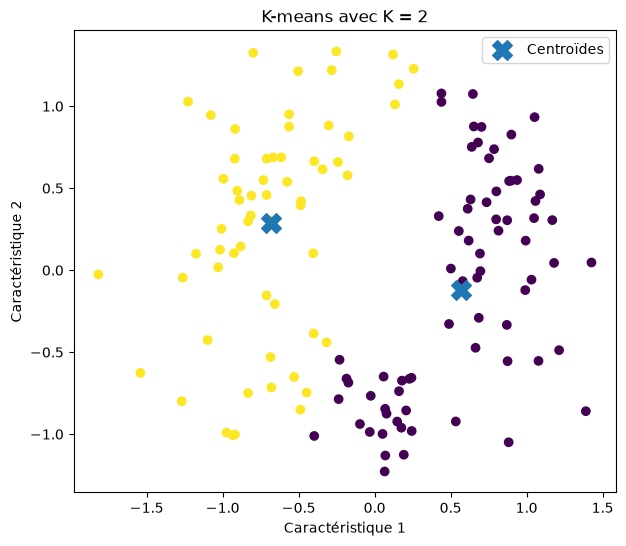

In [15]:
plt.figure(figsize=(7, 6))

plt.scatter(
    data[:, 0],
    data[:, 1],
    c=labels
)

plt.scatter(
    centres[:, 0],
    centres[:, 1],
    marker="X",
    s=200,
    label="Centroïdes"
)

plt.xlabel("Caractéristique 1")
plt.ylabel("Caractéristique 2")
plt.title("K-means avec K = 2")
plt.legend()

plt.show()

In [16]:
for i in range(2):
    print("Cluster", i, ":", np.sum(labels == i), "points")

Cluster 0 : 72 points
Cluster 1 : 60 points


K = 3

In [17]:
np.random.seed(0)

labels3, centres3, inertie3 = kmeans(data, 3)

print("Centroïdes :")
print(centres3)

print("\nInertie intra :", inertie3)

for i in range(3):
    print("Cluster", i, ":", np.sum(labels3 == i), "points")

Centroïdes :
[[-0.25036585 -0.77900488]
 [-0.64751136  0.62248636]
 [ 0.82458298  0.27467234]]

Inertie intra : 40.39311746778141
Cluster 0 : 41 points
Cluster 1 : 44 points
Cluster 2 : 47 points


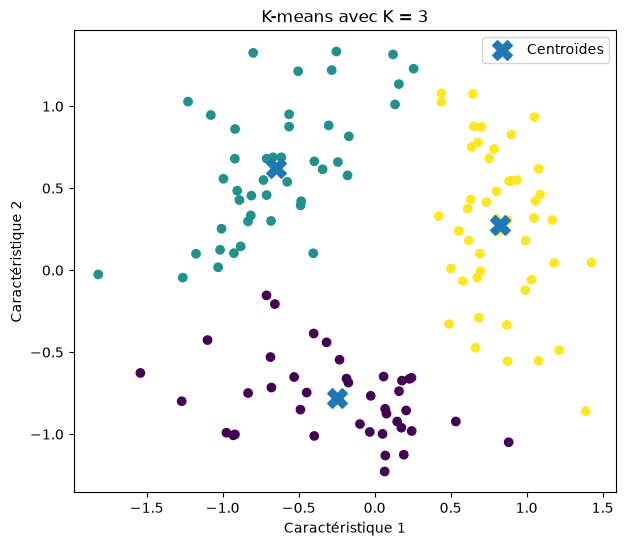

In [18]:
plt.figure(figsize=(7, 6))

plt.scatter(
    data[:, 0],
    data[:, 1],
    c=labels3
)

plt.scatter(
    centres3[:, 0],
    centres3[:, 1],
    marker="X",
    s=200,
    label="Centroïdes"
)

plt.xlabel("Caractéristique 1")
plt.ylabel("Caractéristique 2")
plt.title("K-means avec K = 3")
plt.legend()

plt.show()

K = 2
Inertie = 81.61542362622222
Cardinalités = [np.int64(72), np.int64(60)]
------------------------


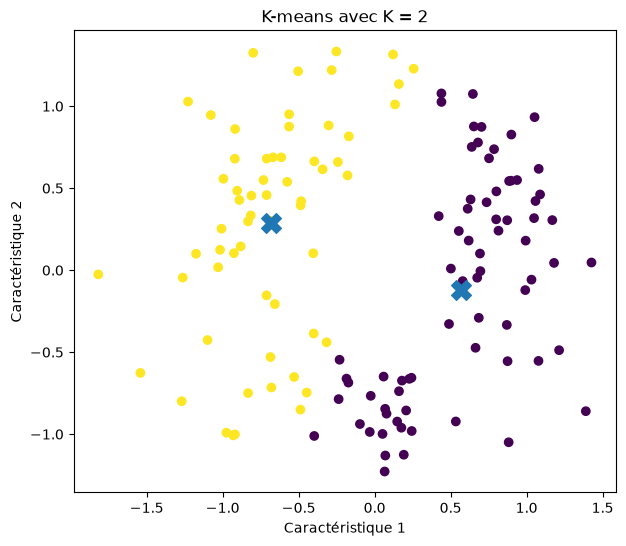

K = 3
Inertie = 40.39311746778141
Cardinalités = [np.int64(41), np.int64(44), np.int64(47)]
------------------------


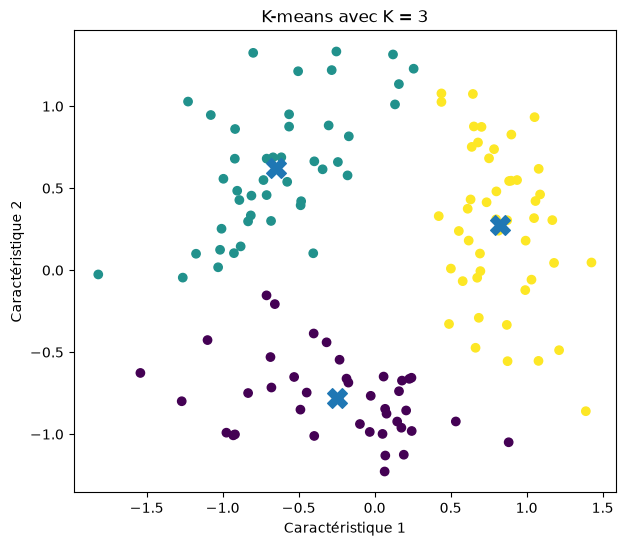

K = 5
Inertie = 24.736532690930282
Cardinalités = [np.int64(16), np.int64(22), np.int64(29), np.int64(42), np.int64(23)]
------------------------


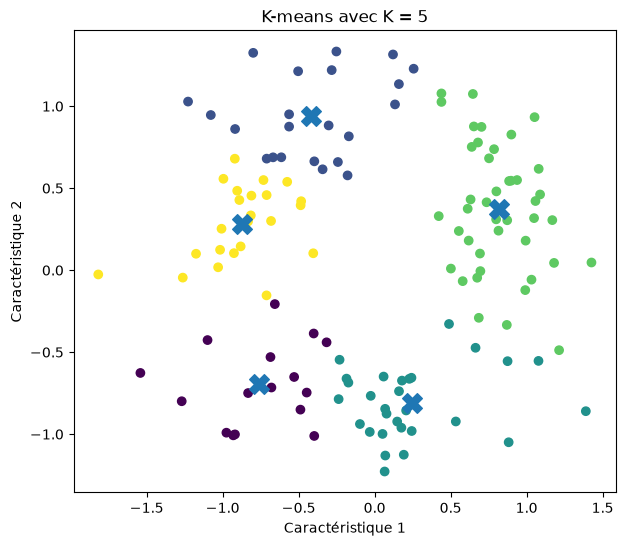

K = 10
Inertie = 12.69927984279539
Cardinalités = [np.int64(3), np.int64(20), np.int64(8), np.int64(27), np.int64(11), np.int64(4), np.int64(18), np.int64(20), np.int64(13), np.int64(8)]
------------------------


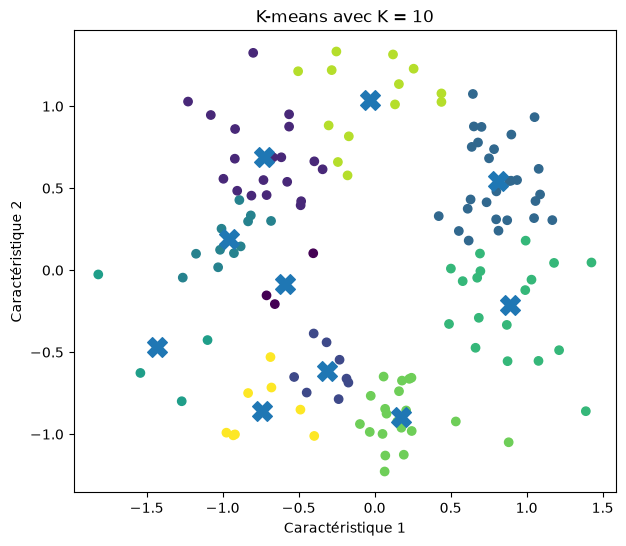

K = 15
Inertie = 8.904617490979437
Cardinalités = [np.int64(3), np.int64(20), np.int64(3), np.int64(16), np.int64(11), np.int64(4), np.int64(10), np.int64(4), np.int64(11), np.int64(6), np.int64(7), np.int64(4), np.int64(15), np.int64(10), np.int64(8)]
------------------------


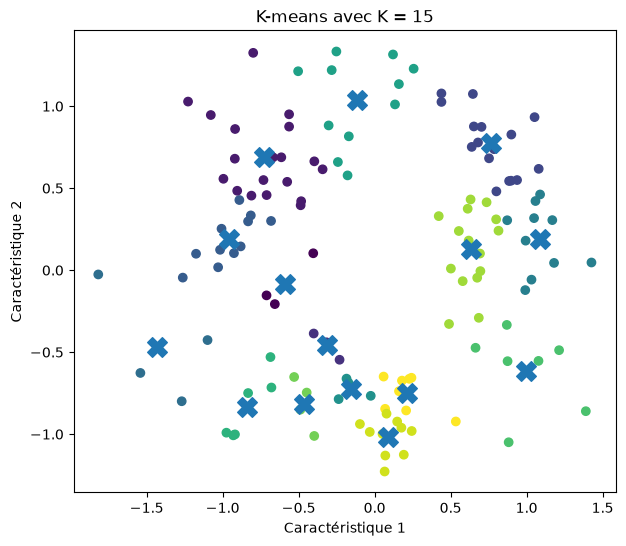

K = 20
Inertie = 6.176279798371601
Cardinalités = [np.int64(3), np.int64(12), np.int64(3), np.int64(4), np.int64(11), np.int64(4), np.int64(4), np.int64(4), np.int64(13), np.int64(6), np.int64(5), np.int64(4), np.int64(8), np.int64(10), np.int64(8), np.int64(6), np.int64(5), np.int64(9), np.int64(5), np.int64(8)]
------------------------


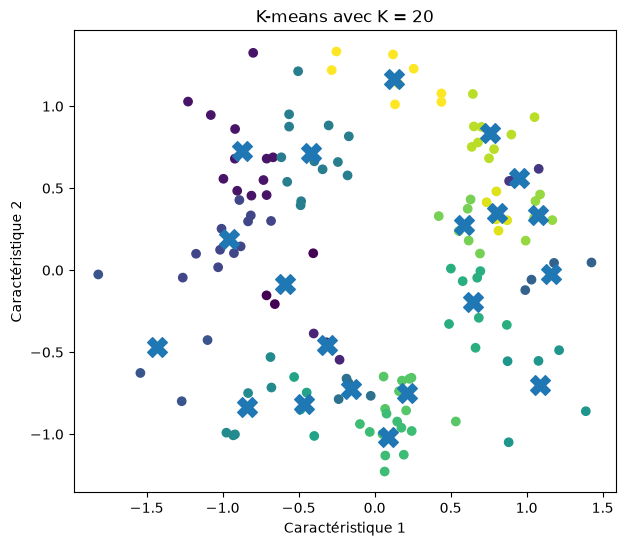

In [19]:
K_values = [2, 3, 5, 10, 15, 20]

resultats = []

for k in K_values:

    np.random.seed(0)
    labels_k, centres_k, inertie_k = kmeans(data, k)

    # Cardinalité de chaque cluster
    cardinalites = []

    for i in range(k):
        cardinalites.append(np.sum(labels_k == i))

    # Sauvegarder les résultats
    resultats.append([k, inertie_k, cardinalites])

    # Affichage
    print("K =", k)
    print("Inertie =", inertie_k)
    print("Cardinalités =", cardinalites)
    print("------------------------")

    # Figure
    plt.figure(figsize=(7, 6))

    plt.scatter(
        data[:, 0],
        data[:, 1],
        c=labels_k
    )

    plt.scatter(
        centres_k[:, 0],
        centres_k[:, 1],
        marker="X",
        s=200
    )

    plt.title("K-means avec K = " + str(k))
    plt.xlabel("Caractéristique 1")
    plt.ylabel("Caractéristique 2")

    plt.show()

K : [2, 3, 5, 10, 15, 20]
Inerties : [np.float64(81.61542362622222), np.float64(40.39311746778141), np.float64(24.736532690930282), np.float64(12.69927984279539), np.float64(8.904617490979437), np.float64(6.176279798371601)]


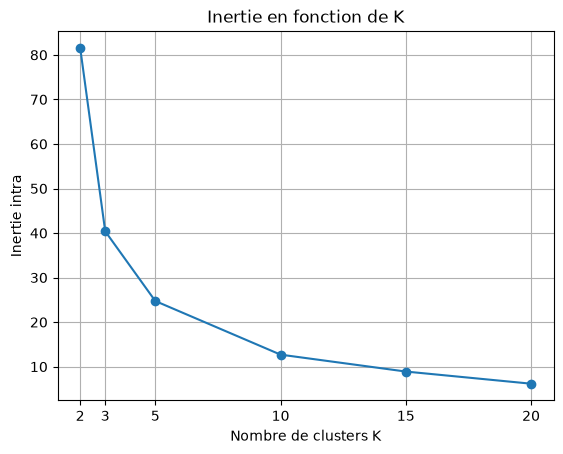

In [20]:
ks = [r[0] for r in resultats]
inerties = [r[1] for r in resultats]

print("K :", ks)
print("Inerties :", inerties)

plt.plot(ks, inerties, marker="o")

plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie intra")
plt.title("Inertie en fonction de K")

plt.xticks(ks)
plt.grid()

plt.show()

In [21]:
resultats_25 = []

for essai in range(25):

    np.random.seed(essai)

    labels_essai, centres_essai, inertie_essai = kmeans(data, 2)

    resultats_25.append(labels_essai)

resultats_25 = np.array(resultats_25)

print(resultats_25.shape)

(25, 132)


In [22]:
n = len(data)

# Au début, chaque point n'est affecté à aucune forme forte
visite = np.zeros(n, dtype=bool)

formes_fortes = []

for i in range(n):

    if not visite[i]:

        groupe = []

        for j in range(n):

            # i et j sont-ils toujours ensemble pendant les 25 essais ?
            toujours_ensemble = np.all(
                resultats_25[:, i] == resultats_25[:, j]
            )

            if toujours_ensemble:
                groupe.append(j)
                visite[j] = True

        formes_fortes.append(groupe)

print("Nombre de formes fortes :", len(formes_fortes))

print("Cardinalités :")
for i, groupe in enumerate(formes_fortes):
    print("Forme forte", i + 1, ":", len(groupe), "points")

Nombre de formes fortes : 15
Cardinalités :
Forme forte 1 : 31 points
Forme forte 2 : 1 points
Forme forte 3 : 7 points
Forme forte 4 : 27 points
Forme forte 5 : 7 points
Forme forte 6 : 18 points
Forme forte 7 : 16 points
Forme forte 8 : 8 points
Forme forte 9 : 5 points
Forme forte 10 : 4 points
Forme forte 11 : 2 points
Forme forte 12 : 1 points
Forme forte 13 : 3 points
Forme forte 14 : 1 points
Forme forte 15 : 1 points


In [23]:
for k in [2, 3, 4, 5]:

    # 25 exécutions de K-means
    classifications = []

    for essai in range(25):

        np.random.seed(essai)

        labels_essai, centres_essai, inertie_essai = kmeans(data, k)

        classifications.append(labels_essai)

    classifications = np.array(classifications)

    # Recherche des formes fortes
    n = len(data)
    visite = np.zeros(n, dtype=bool)
    formes_fortes = []

    for i in range(n):

        if not visite[i]:

            groupe = []

            for j in range(n):

                toujours_ensemble = np.all(
                    classifications[:, i] == classifications[:, j]
                )

                if toujours_ensemble:
                    groupe.append(j)
                    visite[j] = True

            formes_fortes.append(groupe)

    # Résultats
    print("\nK =", k)
    print("Nombre de formes fortes :", len(formes_fortes))
    print("Cardinalités :", [len(g) for g in formes_fortes])


K = 2
Nombre de formes fortes : 15
Cardinalités : [31, 1, 7, 27, 7, 18, 16, 8, 5, 4, 2, 1, 3, 1, 1]

K = 3
Nombre de formes fortes : 10
Cardinalités : [36, 16, 24, 19, 11, 18, 3, 3, 1, 1]

K = 4
Nombre de formes fortes : 34
Cardinalités : [6, 9, 4, 3, 1, 18, 9, 2, 3, 3, 8, 10, 4, 11, 1, 1, 8, 3, 3, 3, 1, 6, 2, 1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1]

K = 5
Nombre de formes fortes : 43
Cardinalités : [7, 9, 4, 4, 2, 18, 9, 2, 2, 1, 5, 4, 6, 1, 4, 4, 1, 2, 3, 1, 3, 1, 2, 6, 4, 1, 3, 2, 2, 1, 1, 3, 2, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1]


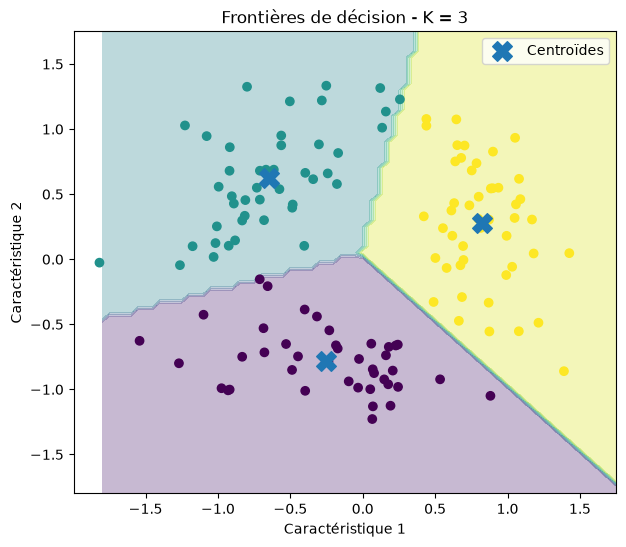

In [24]:
# K-means avec K = 3
np.random.seed(0)
labels3, centres3, inertie3 = kmeans(data, 3)

# Création du maillage de -1.8 à 1.8 avec un pas de 0.05
x = np.arange(-1.8, 1.8, 0.05)
y = np.arange(-1.8, 1.8, 0.05)

xx, yy = np.meshgrid(x, y)

# Transformer le maillage en une liste de points
points_maillage = np.c_[xx.ravel(), yy.ravel()]

# Distance de chaque point du maillage aux 3 centroïdes
distances = np.linalg.norm(
    points_maillage[:, np.newaxis] - centres3,
    axis=2
)

# Chaque point appartient au centroïde le plus proche
Z = np.argmin(distances, axis=1)

# Remettre les résultats sous forme de grille
Z = Z.reshape(xx.shape)

# Affichage
plt.figure(figsize=(7, 6))

plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(
    data[:, 0],
    data[:, 1],
    c=labels3
)

plt.scatter(
    centres3[:, 0],
    centres3[:, 1],
    marker="X",
    s=200,
    label="Centroïdes"
)

plt.xlabel("Caractéristique 1")
plt.ylabel("Caractéristique 2")
plt.title("Frontières de décision - K = 3")
plt.legend()

plt.show()